# Решение задачи кредитного скоринга 
Решение задачи кредитного скоринга будет представлено в нескольких ноутбуках. В данном ноутбуке будет зафиксирована схема валидации, обучена baseline модель градиентного бустинга и проведен отбор признаков с помощью feature importance.

## Данные
Датасет соревнования устроен таким образом, что кредиты для тренировочной выборки взяты за период в М месяцев, а кредиты для тестовой выборки взяты за последующие K месяцев.

Каждая запись кредитной истории содержит самую разнообразную информацию о прошлом кредите клиента, например, сумму, отношение клиента к кредиту, дату открытия и закрытия, информацию о просрочках по платежам и др. Все публикуемые данные тщательно анонимизированы.

Целевая переменная – бинарная величина, принимающая значения 0 и 1, где 1 соответствует дефолту клиента по кредиту.

## Проверка решения
Итоговая метрика решения - ROC AUC. Решения принимаются в виде csv-файла с двумя колонками: “id” – уникальный идентификатор и “score” – предсказание дефолта клиента по кредиту.

## Импорт библиотек

In [1]:
# Импорт библиотек
import sys

sys.path.append('../src')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, roc_auc_score
from xgboost import XGBClassifier

from credit_scoring.validation import time_split

pd.set_option('display.max_rows', 200)
RANDOM_STATE = 13

## Чтение датасета
Прочитаем сагрегированный датасет, сохраненный в артефактах ноутбуком EDA.

In [2]:
# Чтение датасета
train = pd.read_parquet('../artifacts/aggregated_df.parquet')

# XGBoost всё равно работает во float32 - приведём признаки, чтобы вдвое сократить память
feature_cols = [c for c in train.columns if c != 'flag']
train[feature_cols] = train[feature_cols].astype('float32')
print(train.shape)

(3000000, 315)


## Схема валидации
В EDA мы выяснили, что порядок `id` соответствует времени: ранние и поздние заявки отличаются с adversarial ROC-AUC 0.80, а test идёт сразу после train. Поэтому вместо StratifiedKFold с перемешиванием разобьём заявки по времени:
- **train** (первые 60% по `id`) - обучение;
- **valid** (следующие 20%) - все решения: отбор признаков, тюнинг, калибровка, пороги;
- **oot** (последние 20%, out-of-time) - только финальная оценка. Если подбирать что-либо по oot, оценка перестанет быть честной.

Функция разбиения лежит в src/credit_scoring/validation.py, чтобы все ноутбуки использовали одинаковое разбиение.

In [3]:
# Разбиваем заявки по времени
train_df, valid_df, oot_df = time_split(train)
del train

pd.DataFrame({
    name: {'n': len(d), 'id_min': d.index.min(), 'id_max': d.index.max(), 'default_rate': d['flag'].mean()}
    for name, d in {'train': train_df, 'valid': valid_df, 'oot': oot_df}.items()
}).T

,n,id_min,id_max,default_rate
train,1800000.0,0.0,1799999.0,0.036108
valid,600000.0,1800000.0,2399999.0,0.035908
oot,600000.0,2400000.0,2999999.0,0.033172


In [4]:
def fit_eval(features, model=None, fit_df=None, eval_df=None):
    """Обучает модель на fit_df (по умолчанию train) и возвращает модель, ROC-AUC и вероятности на eval_df (по умолчанию valid)."""
    fit_df = train_df if fit_df is None else fit_df
    eval_df = valid_df if eval_df is None else eval_df
    if model is None:
        model = XGBClassifier(tree_method='hist', random_state=RANDOM_STATE)
    model.fit(fit_df[features], fit_df['flag'])
    proba = model.predict_proba(eval_df[features])[:, 1]
    return model, roc_auc_score(eval_df['flag'], proba), proba

## Baseline модель
Обучим градиентный бустинг с параметрами по умолчанию на всех признаках.

In [5]:
# Baseline на всех признаках, оценка на valid
baseline_model, baseline_auc, baseline_proba = fit_eval(feature_cols)
print(f"Valid ROC-AUC (все {len(feature_cols)} признаков): {baseline_auc:.4f}")

Valid ROC-AUC (все 314 признаков): 0.7470


Для сравнения обучим ту же модель на случайном разбиении тех же размеров - так, как валидировали раньше. Разница покажет, насколько случайное разбиение завышает оценку.

In [6]:
# Та же модель на случайном разбиении train + valid
dev = pd.concat([train_df, valid_df])
rnd_valid = dev.sample(len(valid_df), random_state=RANDOM_STATE)
rnd_train = dev.drop(rnd_valid.index)
del dev

_, random_auc, _ = fit_eval(feature_cols, fit_df=rnd_train, eval_df=rnd_valid)
del rnd_train, rnd_valid
print(f"ROC-AUC на случайном разбиении: {random_auc:.4f}")
print(f"ROC-AUC на разбиении по времени: {baseline_auc:.4f}")

ROC-AUC на случайном разбиении: 0.7621
ROC-AUC на разбиении по времени: 0.7470


На случайном разбиении ROC-AUC 0.762, а на разбиении по времени - 0.747. Случайное разбиение завышает оценку примерно на 0.015: модель видит в обучении заявки из того же периода, что и в валидации. Дальше все сравнения ведём только на разбиении по времени.

Также обратим внимание на уровень дефолта: в train и valid он ~3.6%, в oot - 3.3%. Это ещё одно проявление дрейфа, важное для калибровки вероятностей.

### Балансировка классов
Раньше для борьбы с дисбалансом использовался `scale_pos_weight`. Проверим, что он даёт. ROC-AUC - ранговая метрика, а веса классов в основном сдвигают предсказанные вероятности, поэтому сравним ещё log loss и среднюю предсказанную вероятность с фактическим уровнем дефолта.

In [7]:
# Сравним модель без весов и со scale_pos_weight
estimated_weight = (train_df['flag'] == 0).sum() / (train_df['flag'] == 1).sum()
weighted_model = XGBClassifier(tree_method='hist', scale_pos_weight=estimated_weight, random_state=RANDOM_STATE)
_, weighted_auc, weighted_proba = fit_eval(feature_cols, weighted_model)

pd.DataFrame({
    'без весов': {'roc_auc': baseline_auc, 'log_loss': log_loss(valid_df['flag'], baseline_proba), 'mean_proba': baseline_proba.mean()},
    f'scale_pos_weight = {estimated_weight:.1f}': {'roc_auc': weighted_auc, 'log_loss': log_loss(valid_df['flag'], weighted_proba), 'mean_proba': weighted_proba.mean()},
    'факт': {'roc_auc': np.nan, 'log_loss': np.nan, 'mean_proba': valid_df['flag'].mean()},
}).T

,roc_auc,log_loss,mean_proba
без весов,0.747017,0.141386,0.033246
scale_pos_weight = 26.7,0.744213,0.513801,0.358836
факт,NaN,NaN,0.035908


`scale_pos_weight` не помогает: ROC-AUC ниже (0.744 против 0.747), а вероятности сильно искажаются - средняя предсказанная вероятность 0.36 при фактическом уровне дефолта 0.036, log loss вырастает с 0.141 до 0.514. Модель без весов уже почти откалибрована (средняя вероятность 0.033). Поэтому дальше обучаем без `scale_pos_weight`: для ROC-AUC дисбаланс не мешает, а честные вероятности нужны для калибровки и выбора порога.

## Отбор признаков
### Feature importance
Посчитаем важность признаков (gain) только на train части, чтобы valid и oot не участвовали в отборе. Чтобы оценка важности была устойчивой, обучим 5 моделей на случайных половинах train и усредним важность. Признаки ранжируем по средней важности.

In [8]:
# Важность признаков на 5 случайных половинах train
importances = []
for seed in range(5):
    sub = train_df.sample(frac=0.5, random_state=seed)
    model = XGBClassifier(tree_method='hist', importance_type='gain', random_state=seed)
    model.fit(sub[feature_cols], sub['flag'])
    importances.append(pd.Series(model.feature_importances_, index=feature_cols))
del sub
imp = pd.concat(importances, axis=1)

importance_df = pd.DataFrame({
    'mean_importance': imp.mean(axis=1),
    'std_importance': imp.std(axis=1),
    'mean_rank': imp.rank(ascending=False).mean(axis=1),
    'worst_rank': imp.rank(ascending=False).max(axis=1),
}).sort_values('mean_importance', ascending=False)
importance_df.head(30)

,mean_importance,std_importance,mean_rank,worst_rank
paym_last6_s0_share_mean,0.068848,0.006327,1.0,1.0
paym_all_overdue_rate_mean,0.018704,0.002202,3.6,5.0
last3_is_zero_loans3060,0.018083,0.003007,4.0,8.0
enc_loans_credit_type_0_share,0.017027,0.002752,5.2,7.0
pre_util_16_share,0.016255,0.002147,5.8,9.0
last3_is_zero_loans6090,0.016000,0.011727,27.0,80.0
pre_util_3_share,0.015170,0.000996,7.0,9.0
pre_util_6_share,0.014630,0.002174,8.6,12.0
paym_all_s0_share_mean,0.014170,0.001502,9.0,12.0
paym_all_s0_share_max,0.013144,0.003242,10.2,15.0


In [9]:
# Признаки, которые ни одна модель не использовала
unused = importance_df.index[importance_df['mean_importance'] == 0].tolist()
print(f"Не используются ни одной моделью: {len(unused)}")
unused

Не используются ни одной моделью: 24


['pre_over2limit_18_share',
 'pre_loans6090_sum',
 'pre_loans6090_max',
 'pre_loans_total_overdue_sum',
 'pre_loans3060_max',
 'pre_loans_total_overdue_std',
 'paym_last1_s1_share_max',
 'pre_loans_total_overdue_max',
 'pre_loans_total_overdue_mean',
 'enc_loans_account_cur_mode_value',
 'enc_loans_account_holder_type_0_share',
 'paym_last1_s2_share_max',
 'paym_last1_s3_share_max',
 'paym_last1_overdue_rate_max',
 'enc_loans_account_holder_type_2_count',
 'enc_loans_account_holder_type_5_count',
 'enc_loans_account_holder_type_6_count',
 'enc_loans_credit_status_0_count',
 'enc_loans_credit_status_6_count',
 'enc_loans_credit_type_6_count',
 'enc_loans_account_cur_3_share',
 'enc_loans_account_cur_0_count',
 'enc_loans_account_cur_3_count',
 'enc_loans_account_holder_type_0_count']

### Выбор количества признаков
Переберём количество признаков K из ранжированного списка и посмотрим на ROC-AUC на valid. Все модели оцениваются на одной и той же valid выборке, поэтому разницы между K сравнимы между собой.

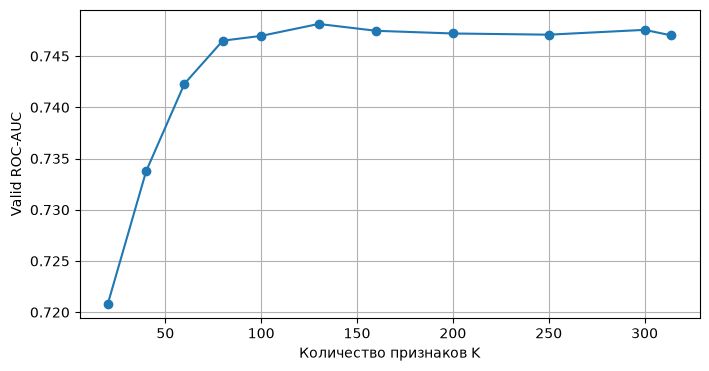

,k,valid_roc_auc
0,20,0.720806
1,40,0.733761
2,60,0.742304
3,80,0.746505
4,100,0.746971
5,130,0.748137
6,160,0.747467
7,200,0.747206
8,250,0.747089
9,300,0.747559


In [10]:
# Перебор количества признаков
k_list = [k for k in [20, 40, 60, 80, 100, 130, 160, 200, 250, 300] if k < len(feature_cols)] + [len(feature_cols)]
rows = []
for k in k_list:
    _, auc, _ = fit_eval(importance_df.index[:k].tolist())
    rows.append({'k': k, 'valid_roc_auc': auc})
k_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
plt.plot(k_df['k'], k_df['valid_roc_auc'], marker='o')
plt.xlabel('Количество признаков K')
plt.ylabel('Valid ROC-AUC')
plt.grid(True)
plt.show()
k_df

Выберем наименьшее K, у которого ROC-AUC отстаёт от лучшего не больше чем на 0.001: меньше признаков - проще модель и её интерпретация, а такая разница на практике несущественна.

In [11]:
# Выбираем наименьшее K в пределах допуска от лучшего результата
TOL = 0.001
best_auc = k_df['valid_roc_auc'].max()
K = int(k_df.loc[k_df['valid_roc_auc'] >= best_auc - TOL, 'k'].min())
selected_features = importance_df.index[:K].tolist()
print(f"Лучший valid ROC-AUC: {best_auc:.4f}, выбрано K = {K}")

Лучший valid ROC-AUC: 0.7481, выбрано K = 130


## Финальная оценка на out-of-time
Оценим выбранный набор признаков и полный набор на oot - самых поздних заявках, которые не участвовали ни в одном решении.

In [12]:
# Оценка на oot
final = {}
for name, feats in {f'top-{K}': selected_features, f'все {len(feature_cols)}': feature_cols}.items():
    model, valid_auc, _ = fit_eval(feats)
    oot_auc = roc_auc_score(oot_df['flag'], model.predict_proba(oot_df[feats])[:, 1])
    final[name] = {'valid_roc_auc': valid_auc, 'oot_roc_auc': oot_auc}
pd.DataFrame(final).T

,valid_roc_auc,oot_roc_auc
top-130,0.748137,0.735345
все 314,0.747017,0.734390


Выводы:
- в топе важности - новые признаки из feature_engineering: доля месяцев без просрочки за последние полгода (`paym_last6_s0_share_mean`) с большим отрывом, доля просрочек среди месяцев с данными, признаки последних кредитов, доли бинов `pre_util` и доли типов кредита;
- 24 признака не используются ни одной моделью - в основном редкие значения категорий и прежние `pre_loans_total_overdue_*`;
- рост ROC-AUC на valid заметен до K = 80-100, лучший результат при K = 130 (0.748), дальше плато с небольшим шумом: 130 признаков дают то же качество, что и все 314, при вдвое меньшем наборе;
- на oot качество ниже, чем на valid (~0.735 против ~0.748): oot дальше по времени от обучающих данных, и дрейф снижает качество. При этом разрыв valid-oot (~0.013) не вырос по сравнению с прежними признаками (~0.016), то есть новые признаки не сделали модель менее устойчивой во времени, несмотря на их дрейф;
- top-130 на oot немного лучше полного набора (0.7353 против 0.7344) - отбор признаков подтверждается и на oot.

## Сохранение
Сохраним выбранные признаки (в том же формате, что читают следующие ноутбуки) и таблицу важности.

In [13]:
# Фиксируем выбранные признаки и таблицу важности
pd.Series(selected_features, name='feature').to_csv('../artifacts/features.csv', header=True)
importance_df.to_csv('../artifacts/feature_importance.csv')

## Итоги
1. Схема валидации по времени: train 60% / valid 20% / oot 20% по порядку `id` (src/credit_scoring/validation.py). Случайное разбиение завышает ROC-AUC примерно на 0.015.
2. `scale_pos_weight` не используется: он не улучшает ROC-AUC и ломает вероятности.
3. Важность признаков считается только на train, усредняется по 5 моделям, признаки ранжируются по средней важности.
4. Из 314 признаков (ноутбук feature_engineering) выбрано 130 (`artifacts/features.csv`), полная таблица важности - в `artifacts/feature_importance.csv`.
5. Оценка baseline на новых признаках: valid ROC-AUC 0.748, oot ROC-AUC 0.735 (на прежних признаках было 0.720 / 0.704).

Далее - тюнинг модели на той же схеме валидации.